In [89]:
from google.colab import files

uploaded = files.upload()

Saving all_stocks_5yr.csv to all_stocks_5yr (1).csv


         date   open   high    low  close    volume Name
0  2013-02-08  15.07  15.12  14.63  14.75   8407500  AAL
1  2013-02-11  14.89  15.01  14.26  14.46   8882000  AAL
2  2013-02-12  14.45  14.51  14.10  14.27   8126000  AAL
3  2013-02-13  14.30  14.94  14.25  14.66  10259500  AAL
4  2013-02-14  14.94  14.96  13.16  13.99  31879900  AAL
(619040, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB
None
date       0
open      11
high       8
low        8
close      0
volume     0
Name       0
dtype: int64


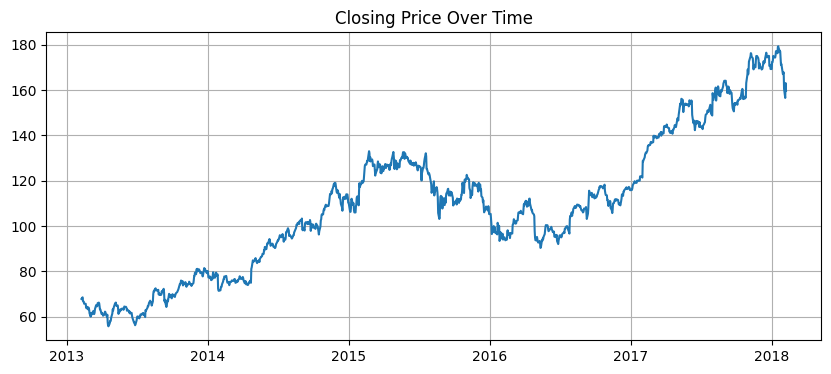

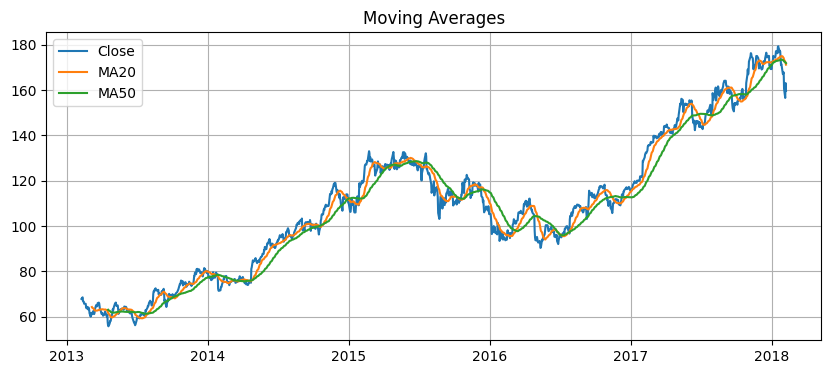

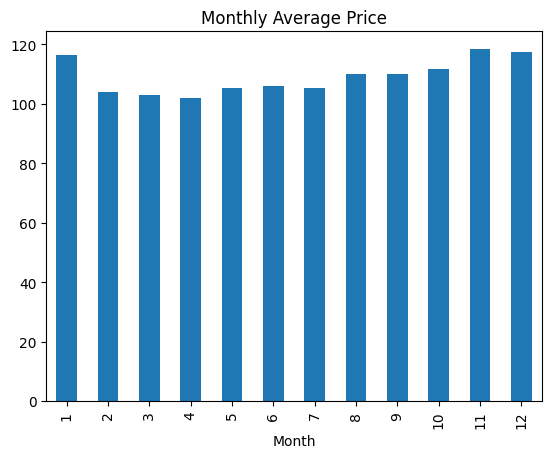

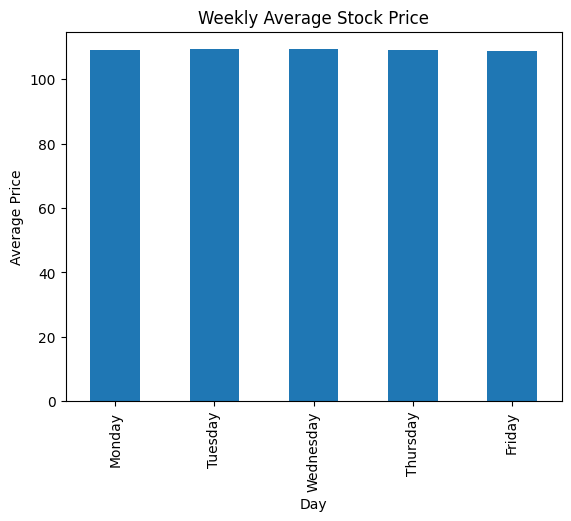

          close   volume
close   1.00000 -0.62029
volume -0.62029  1.00000


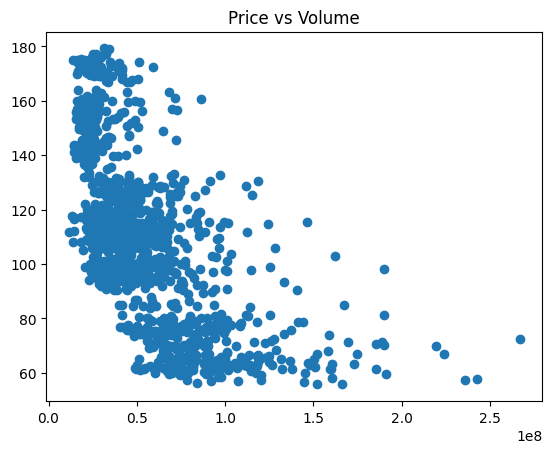

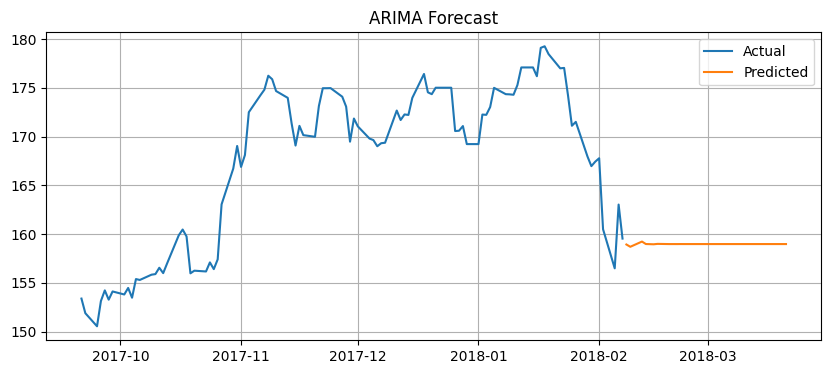

2018-02-08    158.935021
2018-02-09    158.701043
2018-02-12    159.235537
2018-02-13    158.982996
2018-02-14    158.970730
Freq: B, Name: predicted_mean, dtype: float64


In [92]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# 1. Load
df = pd.read_csv('all_stocks_5yr.csv')
print(df.head())

# Display the number of rows and columns in the dataset
print(df.shape)

# Display dataset information such as column names, data types and non-null values
print(df.info())

# Display the number of missing (null) values in each column
print(df.isnull().sum())

# 2. Prepare
df['date'] = pd.to_datetime(df['date'])
stock = df[df['Name'] == 'AAPL'].copy()
stock = stock.sort_values('date')
stock.set_index('date', inplace=True)
stock = stock.sort_index()

# FIX FOR YOUR ERROR - ADD THESE 2 LINES
stock = stock.asfreq('B')
stock['close'] = stock['close'].ffill()

# 3. Price Trend
plt.figure(figsize=(10,4))
plt.plot(stock.index, stock['close'])
plt.title('Closing Price Over Time')
plt.grid()
plt.show()

# 4. Moving Average
stock['MA20'] = stock['close'].rolling(20).mean()
stock['MA50'] = stock['close'].rolling(50).mean()
plt.figure(figsize=(10,4))
plt.plot(stock.index, stock['close'], label='Close')
plt.plot(stock.index, stock['MA20'], label='MA20')
plt.plot(stock.index, stock['MA50'], label='MA50')
plt.legend()
plt.title('Moving Averages')
plt.grid()
plt.show()

# 5. Seasonality
stock['Month'] = stock.index.month
stock.groupby('Month')['close'].mean().plot(kind='bar')
plt.title('Monthly Average Price')
plt.show()


# Weekly Seasonality
stock['Day'] = stock.index.day_name()

weekly = stock.groupby('Day')['close'].mean()

weekly = weekly.reindex([
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday'
])

weekly.plot(kind='bar')
plt.title('Weekly Average Stock Price')
plt.xlabel('Day')
plt.ylabel('Average Price')
plt.show()

# 6. Correlation
print(stock[['close','volume']].corr())
plt.scatter(stock['volume'], stock['close'])
plt.title('Price vs Volume')
plt.show()

# 7. ARIMA - Now will work
model = ARIMA(stock['close'], order=(5,1,0))
model_fit = model.fit()
forecast = model_fit.forecast(steps=30)

plt.figure(figsize=(10,4))
plt.plot(stock.index[-100:], stock['close'].tail(100), label='Actual')
plt.plot(forecast.index, forecast.values, label='Predicted')
plt.title('ARIMA Forecast')
plt.legend()
plt.grid()
plt.show()

print(forecast.head())